# Lake Michigan–Huron level forecasting: main

This notebook runs the analysis: the ideas behind the models, the backtest and the figures, one idea at a time. Each section gives the intuition first, then the code.

Nothing is defined here. Every function and class lives in `function_declaration.ipynb`; the next cell loads them. Run `data_processing.ipynb` first, then run the cells here top to bottom (the backtest in section 6 takes about 7 minutes).

In [1]:
%run ./function_declaration.ipynb
from IPython.display import Image, display

## 0. Load the monthly table

The raw files are turned into one table, one row per month, in `data_processing.ipynb`. That notebook writes `data/processed/monthly.csv`; here we only read it.

In [2]:
df = load_monthly()
df.tail()

,level_m,precip_mm,evap_mm,runoff_mm,frac_gauged_mic,frac_gauged_hur,nbs_mm,dlevel_mm,snow_mic,rain_mic,pdd_mic,snow_hur,rain_hur,pdd_hur
month,,,,,,,,,,,,,,
2023-08,176.70,87.0086,62.9977,24.5482,0.974,0.828,48.5591,0.0,0.00,85.68,613.535,0.00,97.55,571.360
2023-09,176.64,47.3090,44.0508,18.0159,0.974,0.828,21.2741,-60.0,0.00,50.38,525.520,0.00,33.33,500.005
2023-10,176.56,112.1858,79.4914,26.1452,0.979,0.828,58.8396,-80.0,0.00,116.68,346.410,0.00,98.22,336.110
2023-11,176.51,52.1705,100.1989,28.9006,0.960,0.828,-19.1278,-50.0,10.05,30.80,123.255,7.80,40.35,96.525
2023-12,176.44,47.4808,61.2137,35.6816,0.941,0.828,21.9487,-70.0,0.98,48.32,80.330,2.88,46.72,75.370


## 1. The lake as a bathtub

**Intuition.** The lake level goes up when more water comes in than leaves. Water comes in as rain on the lake (P) and river runoff (R); it leaves by evaporation (E) and through the St. Clair River. `nbs_mm` = P − E + R is the *net basin supply*: how many millimetres the lake would rise in a month if nothing flowed out.

Runoff arrives in m³/s, so `runoff_to_depth_mm` spreads that volume over the lake's 117,400 km² to turn it into millimetres. Check one month by hand:

In [3]:
print(f"{1500 * 30 * 86_400 / 117_400e6 * 1000:.1f} mm")  # 1500 m^3/s, a typical runoff, for 30 days over 117,400 km^2

33.1 mm


**Figure 9.** The whole water balance in one picture:

wrote figures/fig9_lake_system.png


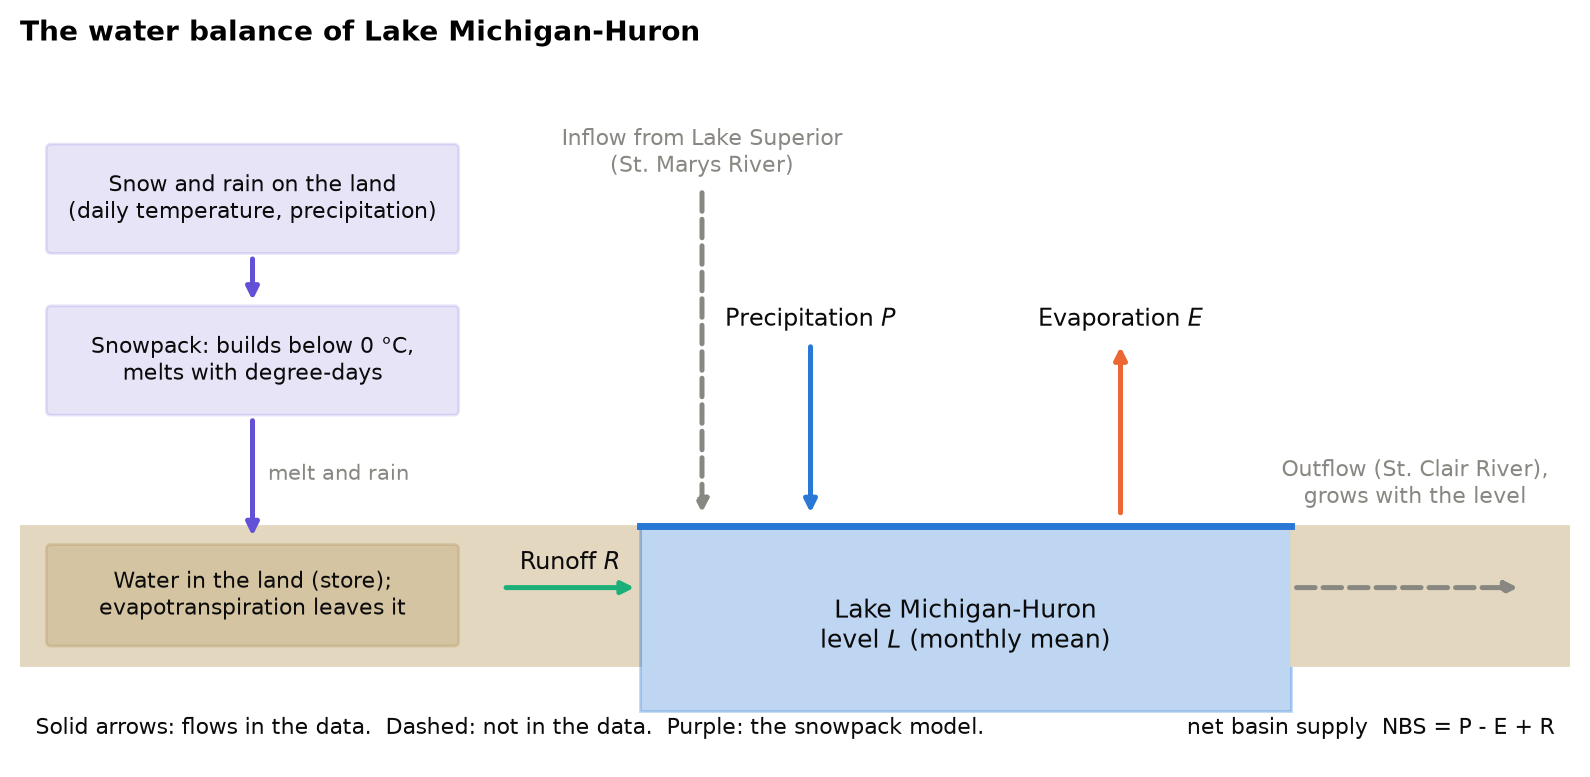

In [4]:
fig9_lake_system()
display(Image(str(FIGURES / "fig9_lake_system.png"), width=800))

## 2. Why predict the *change*, not the level

**Intuition.** The level this month is almost identical to last month's, so a model that just copies the last value looks brilliant if you score the level directly. Predicting the change removes that free ride.

In [5]:
print('correlation of level with last month:       ', round(df.level_m.autocorr(1), 3))
print('correlation of level CHANGE with last month:', round(df.dlevel_mm.autocorr(1), 3))

correlation of level with last month:        0.987
correlation of level CHANGE with last month: 0.703


## 3. Does the bathtub picture hold?

**Intuition.** If the water budget is right, level change should track NBS with a slope near 1. The levels are monthly *averages*, so the change between two averages straddles two months of supply; we average NBS over this month and last month. This is Figure 2 of the report.

wrote figures/fig2_water_balance_check.png
{'r': 0.81, 'slope': 1.07, 'intercept': -68.63}


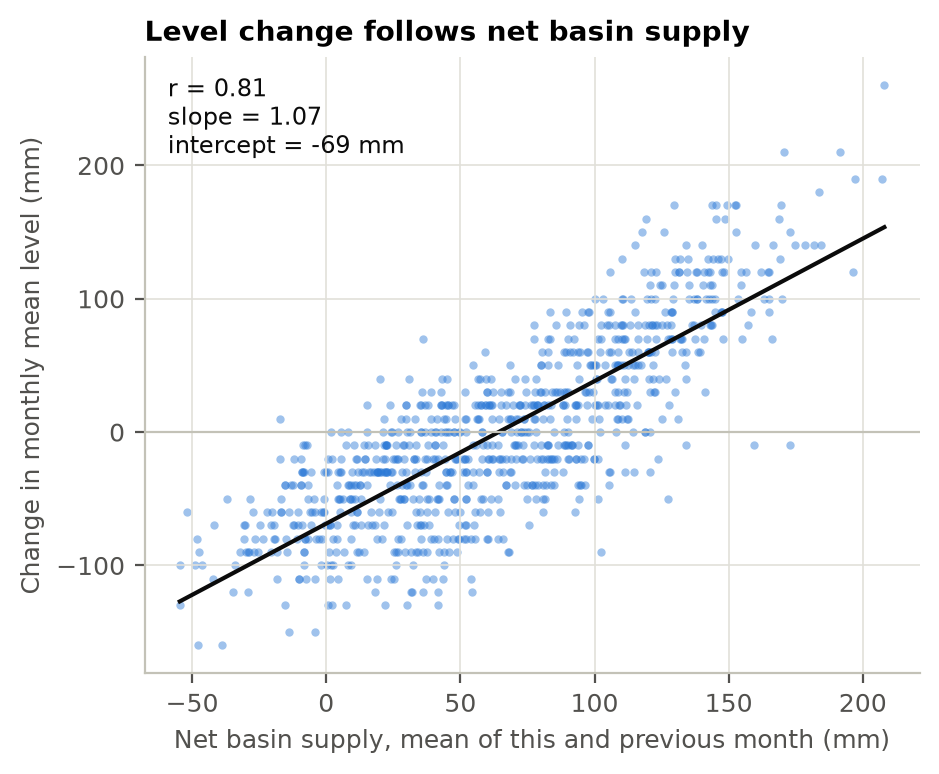

In [6]:
print({k: round(float(v), 2) for k, v in fig2_water_balance(df).items()})
display(Image(str(FIGURES / "fig2_water_balance_check.png"), width=450))

The slope is close to 1. The intercept (about −69 mm/month) is the water that leaves through the rivers on average, which we have no data for.

## 4. The seasonal cycle is a strong baseline

**Intuition.** The lake rises every spring (snowmelt) and falls every autumn (evaporation). A forecast that only knows the calendar already does well, so any model has to beat *this*, not just persistence.

In [7]:
clim = SeasonalClimatology().fit(df)
(clim.mean_change_ / 10).round(1).rename('average level change (cm)').to_frame().T

,1,2,3,4,5,6,7,8,9,10,11,12
average level change (cm),-3.7,-1.8,1.5,8.5,9.8,6.4,3.1,-1.7,-5.1,-6.5,-5.5,-4.3


## 5. The water-balance model

**Intuition.** A regression shaped like the bathtub: level change = supply terms (this month and last) + a monthly constant + a term that lets outflow grow when the lake is high. Coefficients near +1 for P and R and −1 for E would mean a perfect water budget.

In [8]:
wb = WaterBalance().fit(df)
c = wb.coefficients()
print('P  (lag0 + lag1):', round(c['precip_mm_lag0'] + c['precip_mm_lag1'], 2))
print('E  (lag0 + lag1):', round(c['evap_mm_lag0'] + c['evap_mm_lag1'], 2))
print('R  (lag0 + lag1):', round(c['runoff_mm_lag0'] + c['runoff_mm_lag1'], 2))
print('level (mm per m):', round(c['level_m'], 1))

P  (lag0 + lag1): 0.88
E  (lag0 + lag1): -0.81
R  (lag0 + lag1): 1.83
level (mm per m): -23.0


P and E are near ±1 and the level term is negative, as expected. Runoff is well above 1, which means it is standing in for something unmeasured (see the report's limitations).

**To forecast**, we do not know next month's weather. The model fills it in with the seasonal average plus a fading share of the latest anomaly. How fast does an anomaly fade?

In [9]:
dict(zip(['precip', 'evap', 'runoff'], wb.phi_.round(2).tolist()))

{'precip': 0.02, 'evap': 0.26, 'runoff': 0.45}

Precipitation anomalies do not carry over at all (≈0); runoff carries over about half. This is why skill fades quickly with horizon.

## 5b. The lake model

**Intuition.** The same bathtub, but simulated instead of fitted as a regression: the lake fills
with P − E + R and the channel flow, and drains faster when it is high, like water over a weir
(outflow grows with the depth to the power 1.5). It is stepped ten times a month and averaged,
because the observed levels are monthly means. The scaling factors for P, E and R show how far
the budget is from closing with the raw estimates (1 would be a closed budget).

In [10]:
lake = LakeModel().fit(df)
dict(zip(["mP", "mE", "mR", "c (mm/month)", "d (m)"], lake.p_[[0, 1, 2, 15, 16]].round(2).tolist()))

{'mP': 1.0, 'mE': 0.86, 'mR': 1.73, 'c (mm/month)': 24.72, 'd (m)': 1.5}

P and E are close to 1. Runoff is again well above 1, as in the water-balance regression, so the missing channel flows are still being absorbed by the runoff term. `d` sits at its lower bound of 1.5 m: the data ask for an outflow that bends more sharply with level than the bound allows.

## 5c. The snowpack

**Intuition.** Snow that falls on the land in winter does not reach the lake until it melts in spring, so a big snowpack at the end of winter means extra runoff in the months ahead. The AR(1) runoff forecast cannot see the snowpack; this model simulates it from the daily over-land temperature and precipitation. Fitted on the full record:

In [11]:
snow = SnowRunoff().fit(df)
dict(zip(["ddf", "k", "e", "a_mic", "a_hur"], snow.p_.round(3).tolist()))

{'ddf': 2.594, 'k': 0.343, 'e': 0.131, 'a_mic': 0.551, 'a_hur': 0.453}

**Figure 8.** Does the simulated snowpack really turn into runoff? Its seasonal cycle, and the end-of-March snowpack of every year against the runoff of the following April to June:

wrote figures/fig8_snowpack.png
correlation of the end-of-March snowpack with April-June runoff: 0.31


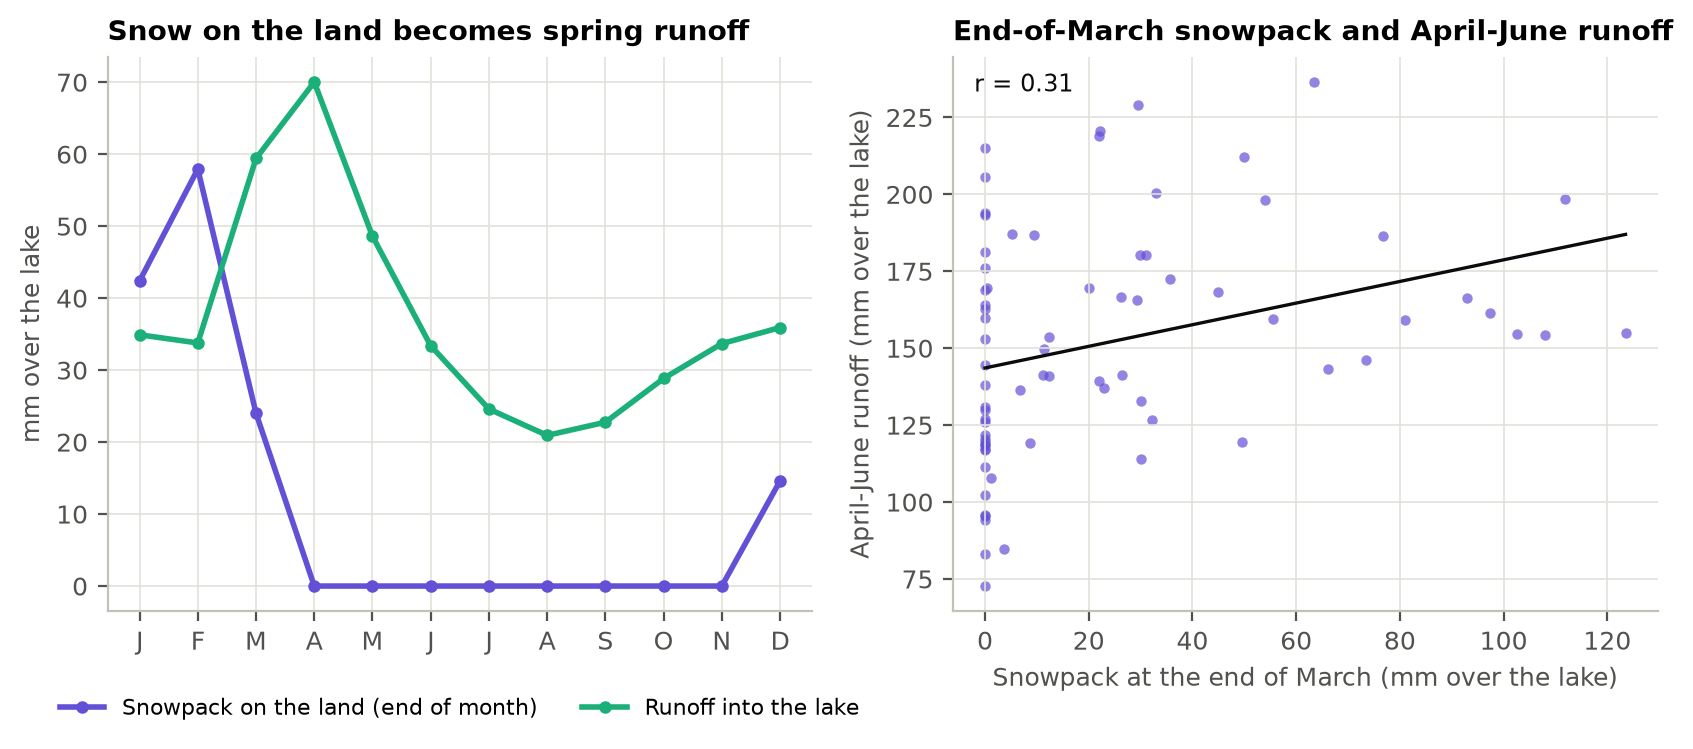

In [12]:
print("correlation of the end-of-March snowpack with April-June runoff:", round(float(fig8_snowpack(snow, df)), 2))
display(Image(str(FIGURES / "fig8_snowpack.png"), width=800))

## 6. Rolling-origin backtest

**Intuition.** To test honestly, a model must never see the year it is tested on. For each year from 1980 on, we train on everything before it, forecast that year, then step forward. `backtest` does this for every model and every forecast is saved to `data/processed/predictions.csv`.

This cell takes about 7 minutes.

wrote figures/fig10_backtest.png


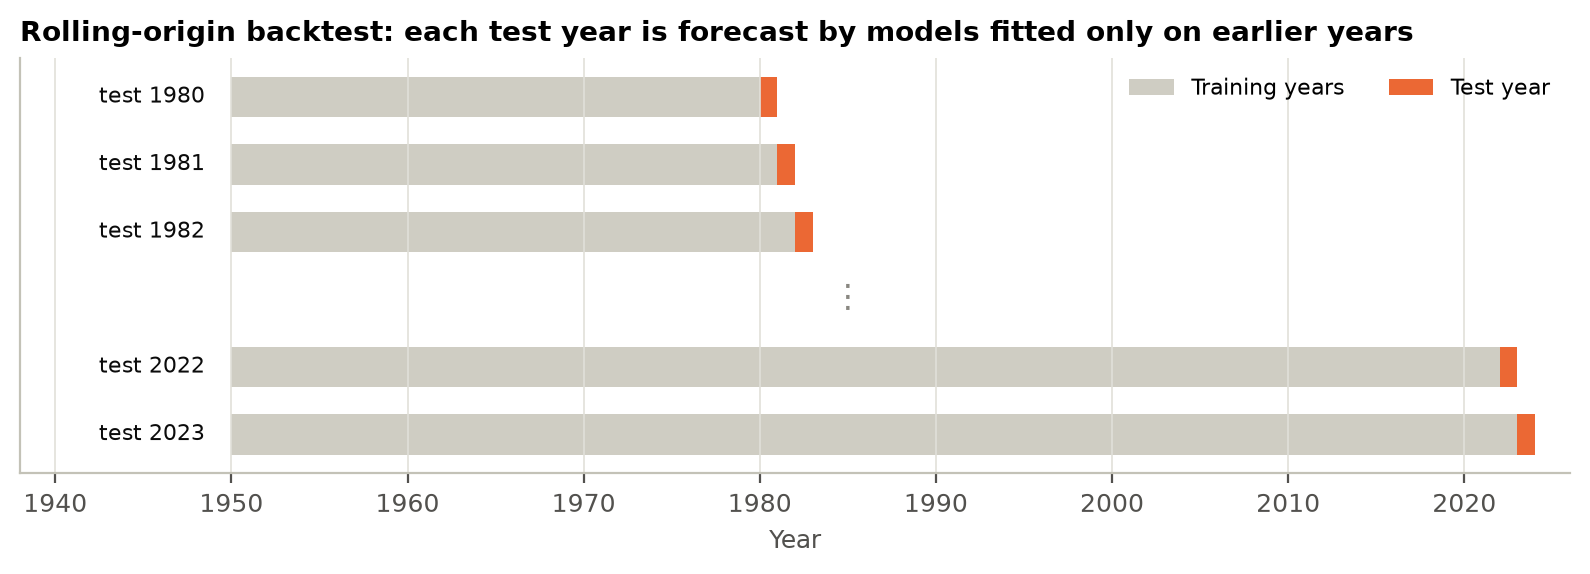

In [13]:
fig10_backtest()
display(Image(str(FIGURES / "fig10_backtest.png"), width=800))

In [14]:
preds = backtest(df)
preds.to_csv(PROCESSED / "predictions.csv", index=False, float_format="%.4f")

table = rmse_table(preds)
table.to_csv(PROCESSED / "rmse_by_horizon.csv", float_format="%.3f")
years = preds["target"].dt.year
print(f"\nRMSE (cm) by horizon, test years {years.min()}-{years.max()}, "
      f"{preds['target'].nunique()} target months")
table.round(2)


RMSE (cm) by horizon, test years 1980-2023, 528 target months


horizon,1,2,3,4,5,6
model,,,,,,
Persistence,6.73,12.37,17.06,20.73,23.30,24.81
Seasonal climatology,4.14,7.06,9.48,11.63,13.53,15.27
Water balance,3.22,6.33,8.82,11.03,12.96,14.66
Water balance + snowpack,3.22,6.26,8.67,10.79,12.66,14.25
Lake model,3.26,6.38,8.88,11.12,13.08,14.78
Lake model + snowpack,3.25,6.30,8.73,10.89,12.79,14.40
Gradient boosting,3.32,6.51,9.12,11.40,13.48,15.39
Gradient boosting + snowpack,3.31,6.49,9.02,11.30,13.55,15.14
Hybrid (WB + GB residual),3.26,6.35,8.95,11.18,13.00,14.58


Reload the saved forecasts, so everything below uses exactly what is on disk:

In [15]:
preds = pd.read_csv(PROCESSED / "predictions.csv")
for col in ("target", "origin"):
    preds[col] = pd.PeriodIndex(preds[col], freq="M")
rmse_table(preds).round(2)

horizon,1,2,3,4,5,6
model,,,,,,
Persistence,6.73,12.37,17.06,20.73,23.30,24.81
Seasonal climatology,4.14,7.06,9.48,11.63,13.53,15.27
Water balance,3.22,6.33,8.82,11.03,12.96,14.66
Water balance + snowpack,3.22,6.26,8.67,10.79,12.66,14.25
Lake model,3.26,6.38,8.88,11.12,13.08,14.78
Lake model + snowpack,3.25,6.30,8.73,10.89,12.79,14.40
Gradient boosting,3.32,6.51,9.12,11.40,13.48,15.39
Gradient boosting + snowpack,3.31,6.49,9.02,11.30,13.55,15.14
Hybrid (WB + GB residual),3.26,6.35,8.95,11.18,13.00,14.58


**Reading the table (RMSE in cm, lower is better).** Everything beats persistence. Water balance + snowpack is best at every horizon (tied with the plain water balance at one month); gradient boosting, the lake model and the physics-guided CNN are slightly worse than the plain water balance. Is that gap real? Resample whole test years and look at the 95% interval of the difference:

In [16]:
bootstrap_rmse_diff(preds, 'Gradient boosting', 'Water balance').round(2)

,diff_cm,ci_low,ci_high
horizon,,,
1,0.10,-0.02,0.23
2,0.18,-0.07,0.44
3,0.30,-0.09,0.68
4,0.38,-0.15,0.92
5,0.52,-0.16,1.21
6,0.73,-0.14,1.63


Every interval includes zero: gradient boosting is not *significantly* worse, but there is no sign it is better.

The row `WB, perfect forcing` is not a forecast. It uses the weather that actually happened, and shows how much error is simply not knowing the future.

The same comparison for the other pairs of models:

In [17]:
for a, b in [("Water balance + snowpack", "Water balance"),
             ("Gradient boosting + snowpack", "Gradient boosting"),
             ("Lake model + snowpack", "Lake model"),
             ("Lake model", "Water balance"),
             ("Physics-guided CNN", "Lake model"),
             ("Hybrid (WB + GB residual)", "Water balance"),
             ("Gradient boosting", "Seasonal climatology"),
             ("Water balance", "Seasonal climatology")]:
    print(f"\nRMSE({a}) - RMSE({b}), cm; negative = first is better")
    print(bootstrap_rmse_diff(preds, a, b).round(2).to_string())


RMSE(Water balance + snowpack) - RMSE(Water balance), cm; negative = first is better
         diff_cm  ci_low  ci_high
horizon                          
1          -0.00   -0.04     0.04
2          -0.08   -0.20     0.08
3          -0.15   -0.35     0.07
4          -0.23   -0.51     0.09
5          -0.31   -0.62     0.04
6          -0.41   -0.76    -0.01

RMSE(Gradient boosting + snowpack) - RMSE(Gradient boosting), cm; negative = first is better


         diff_cm  ci_low  ci_high
horizon                          
1          -0.01   -0.04     0.01
2          -0.02   -0.13     0.09
3          -0.09   -0.26     0.07
4          -0.10   -0.34     0.18
5           0.07   -0.29     0.45
6          -0.25   -0.69     0.25

RMSE(Lake model + snowpack) - RMSE(Lake model), cm; negative = first is better
         diff_cm  ci_low  ci_high
horizon                          
1          -0.01   -0.04     0.02
2          -0.08   -0.19     0.05
3          -0.15   -0.32     0.05
4          -0.22   -0.47     0.07
5          -0.29   -0.58     0.03
6          -0.38   -0.72    -0.01

RMSE(Lake model) - RMSE(Water balance), cm; negative = first is better


         diff_cm  ci_low  ci_high
horizon                          
1           0.05    0.02     0.07
2           0.05    0.00     0.09
3           0.07    0.00     0.13
4           0.09    0.01     0.17
5           0.11    0.01     0.21
6           0.12   -0.00     0.24

RMSE(Physics-guided CNN) - RMSE(Lake model), cm; negative = first is better
         diff_cm  ci_low  ci_high
horizon                          
1          -0.00   -0.01     0.01
2          -0.01   -0.03     0.01
3          -0.01   -0.06     0.02
4          -0.02   -0.11     0.06
5          -0.03   -0.15     0.10
6          -0.02   -0.19     0.14

RMSE(Hybrid (WB + GB residual)) - RMSE(Water balance), cm; negative = first is better


         diff_cm  ci_low  ci_high
horizon                          
1           0.05   -0.04     0.13
2           0.01   -0.17     0.19
3           0.13   -0.18     0.45
4           0.15   -0.29     0.62
5           0.03   -0.53     0.62
6          -0.08   -0.78     0.65

RMSE(Gradient boosting) - RMSE(Seasonal climatology), cm; negative = first is better
         diff_cm  ci_low  ci_high
horizon                          
1          -0.81   -1.05    -0.58
2          -0.55   -0.97    -0.13
3          -0.37   -0.95     0.21
4          -0.22   -0.96     0.48
5          -0.04   -0.90     0.82
6           0.12   -1.01     1.20

RMSE(Water balance) - RMSE(Seasonal climatology), cm; negative = first is better


         diff_cm  ci_low  ci_high
horizon                          
1          -0.92   -1.12    -0.70
2          -0.73   -1.17    -0.28
3          -0.67   -1.26    -0.08
4          -0.60   -1.41     0.20
5          -0.56   -1.59     0.48
6          -0.61   -1.99     0.65


The physics-guided CNN starts as the lake model and only moves away from it in years where early stopping found a better epoch on held-out training months:

In [18]:
t = preds.pivot_table(index="target", columns="model", values="predicted_m")
print("CNN differs from the lake model in:", sorted(set(t.index[(t["Physics-guided CNN"] - t["Lake model"]).abs() > 1e-9].year)))

CNN differs from the lake model in: [2001, 2002, 2003, 2004, 2007]


## 6b. Forecast ranges

**Intuition.** A single number hides how uncertain a forecast is. The water-balance model is run once for every past year, with that year's weather anomalies added to the AR(1) weather forecast, and the spread of the results gives a range. Only years before the test year are used. A good 80% range should hold the observed level about 80% of the time. The weather is not the only source of error, so the errors the model makes on the training years even with the observed weather are added too; the weather-only ranges are kept for comparison.

wrote figures/fig7_forecast_ranges.png


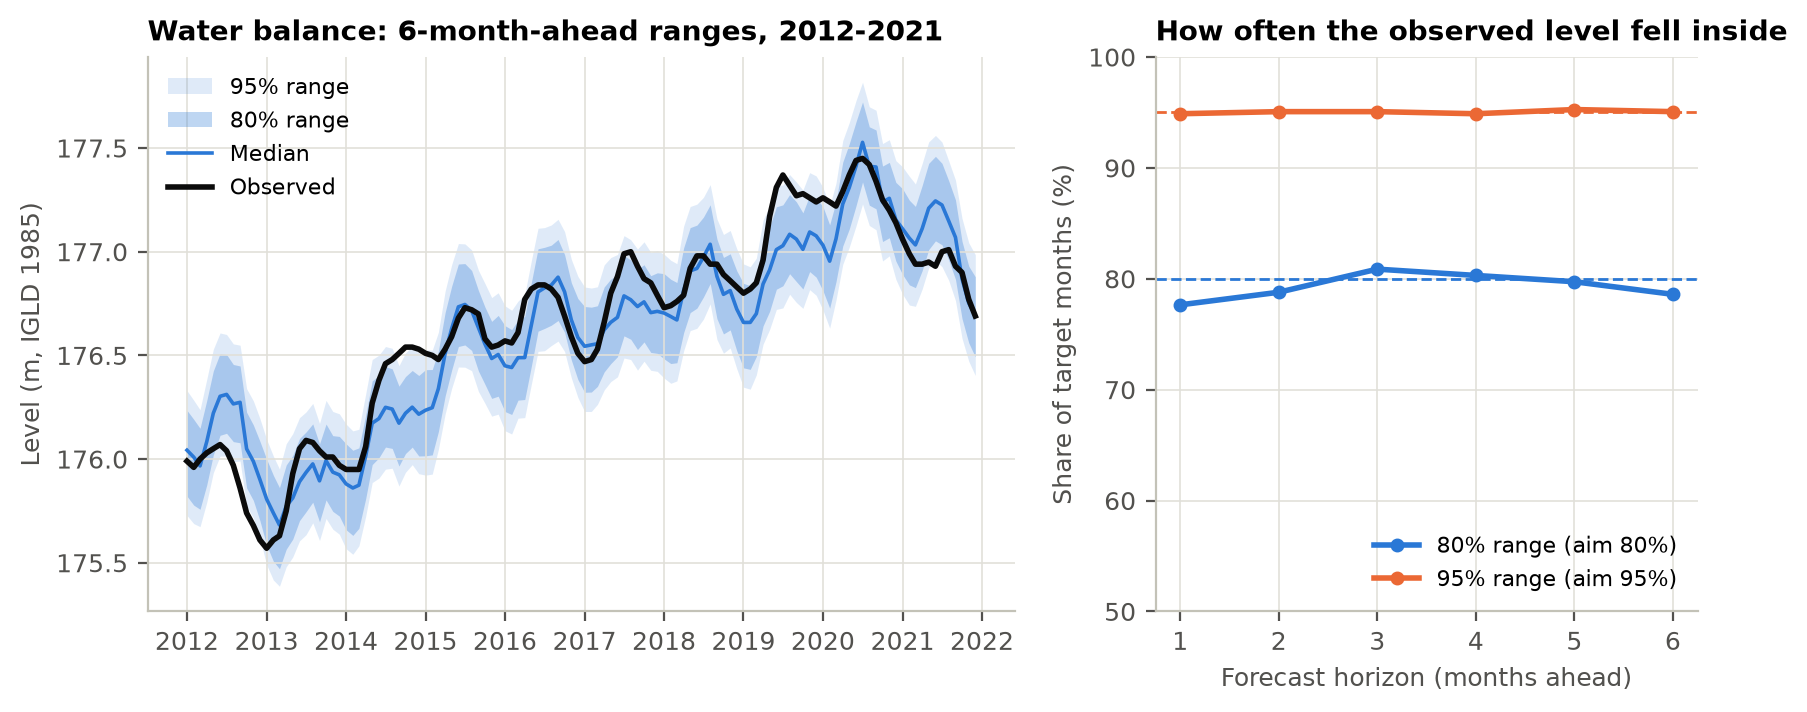

median width of the 80% range (cm): {1: 8.1, 2: 16.3, 3: 23.2, 4: 29.1, 5: 34.5, 6: 39.1}
weather only, % inside the 80% and 95% ranges: {1: (59.8, 76.1), 2: (69.1, 84.7), 3: (70.8, 86.0), 4: (70.6, 86.4), 5: (70.8, 87.5), 6: (72.7, 85.4)}


,80% range,95% range
horizon,,
1,77.7,94.9
2,78.8,95.1
3,80.9,95.1
4,80.3,94.9
5,79.7,95.3
6,78.6,95.1


In [19]:
ranges = ensemble_backtest(df, model_error=True)  # about two minutes, with the weather-only ranges
weather_only = ensemble_backtest(df)
ranges.to_csv(PROCESSED / "forecast_ranges.csv", index=False, float_format="%.4f")
cover = fig7_ranges(ranges, df)
display(Image(str(FIGURES / "fig7_forecast_ranges.png"), width=800))
print("median width of the 80% range (cm):", (100 * (ranges["q0.9"] - ranges["q0.1"])).groupby(ranges["horizon"]).median().round(1).to_dict())
print("weather only, % inside the 80% and 95% ranges:", {h: (round(float(100 * g["observed_m"].between(g["q0.1"], g["q0.9"]).mean()), 1), round(float(100 * g["observed_m"].between(g["q0.025"], g["q0.975"]).mean()), 1)) for h, g in weather_only.groupby("horizon")})
cover.round(1)

## 7. Figures

Each call writes one report figure to `figures/` and the cell then shows it.

**Figure 1.** The data: the level record, and how each supply term varies through the year.

wrote figures/fig1_data_overview.png


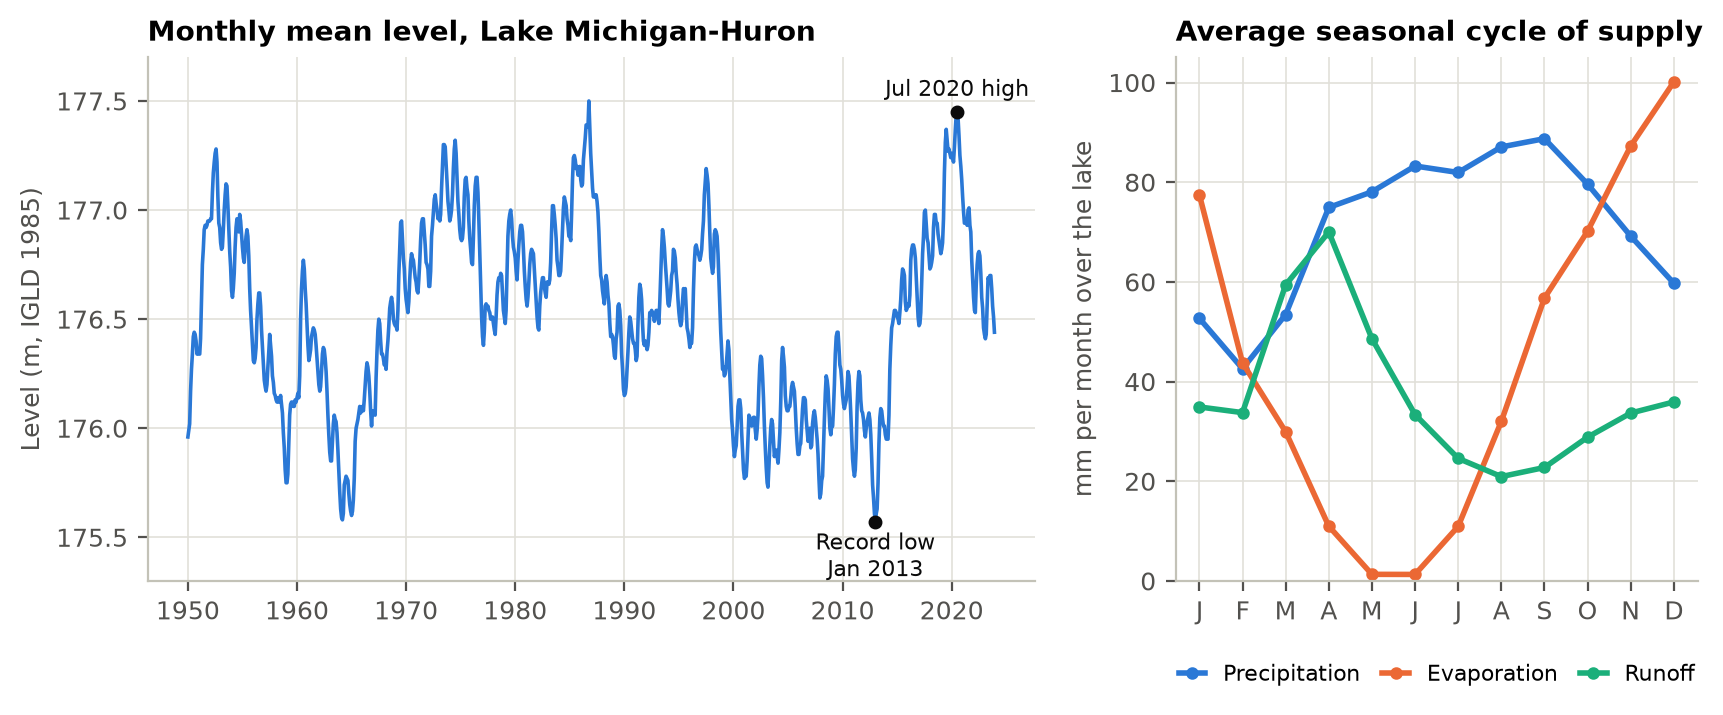

In [20]:
fig1_data(df)
display(Image(str(FIGURES / "fig1_data_overview.png"), width=800))

**Figure 3.** Error by horizon for every model, and how much each improves on the seasonal baseline.

wrote figures/fig3_rmse_by_horizon.png


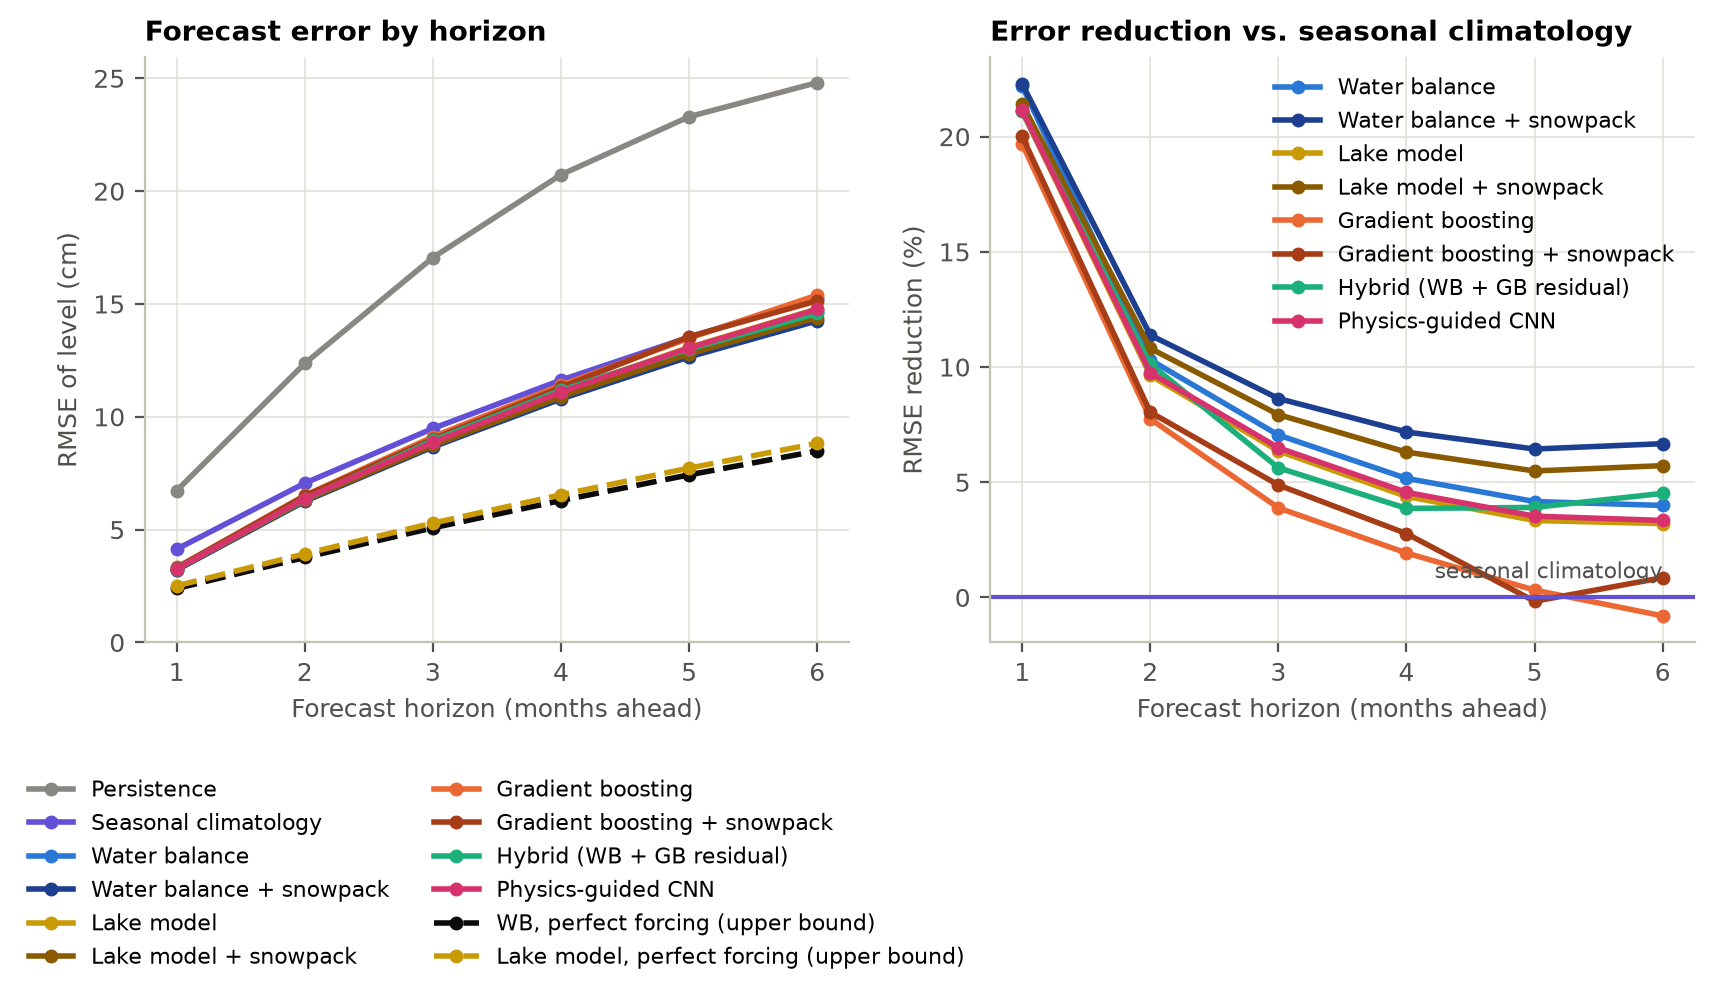

In [21]:
fig3_rmse(preds)
display(Image(str(FIGURES / "fig3_rmse_by_horizon.png"), width=800))

**Figure 4.** Which inputs the gradient-boosting model actually uses. Shuffle one
group of inputs and see how much the error grows; a big increase means the model
depended on it.

                              1      3     6
Accumulated NBS (3-12 mo)  0.04  -0.16 -0.08
Current level              0.10   0.39  1.10
Evaporation                0.93   0.37  8.84
Precipitation              0.60   0.52  0.05
Recent level change        0.77   0.90  2.00
Runoff                     1.55   0.74  1.11
Season (month)             1.18  10.48  1.73
wrote figures/fig4_feature_importance.png


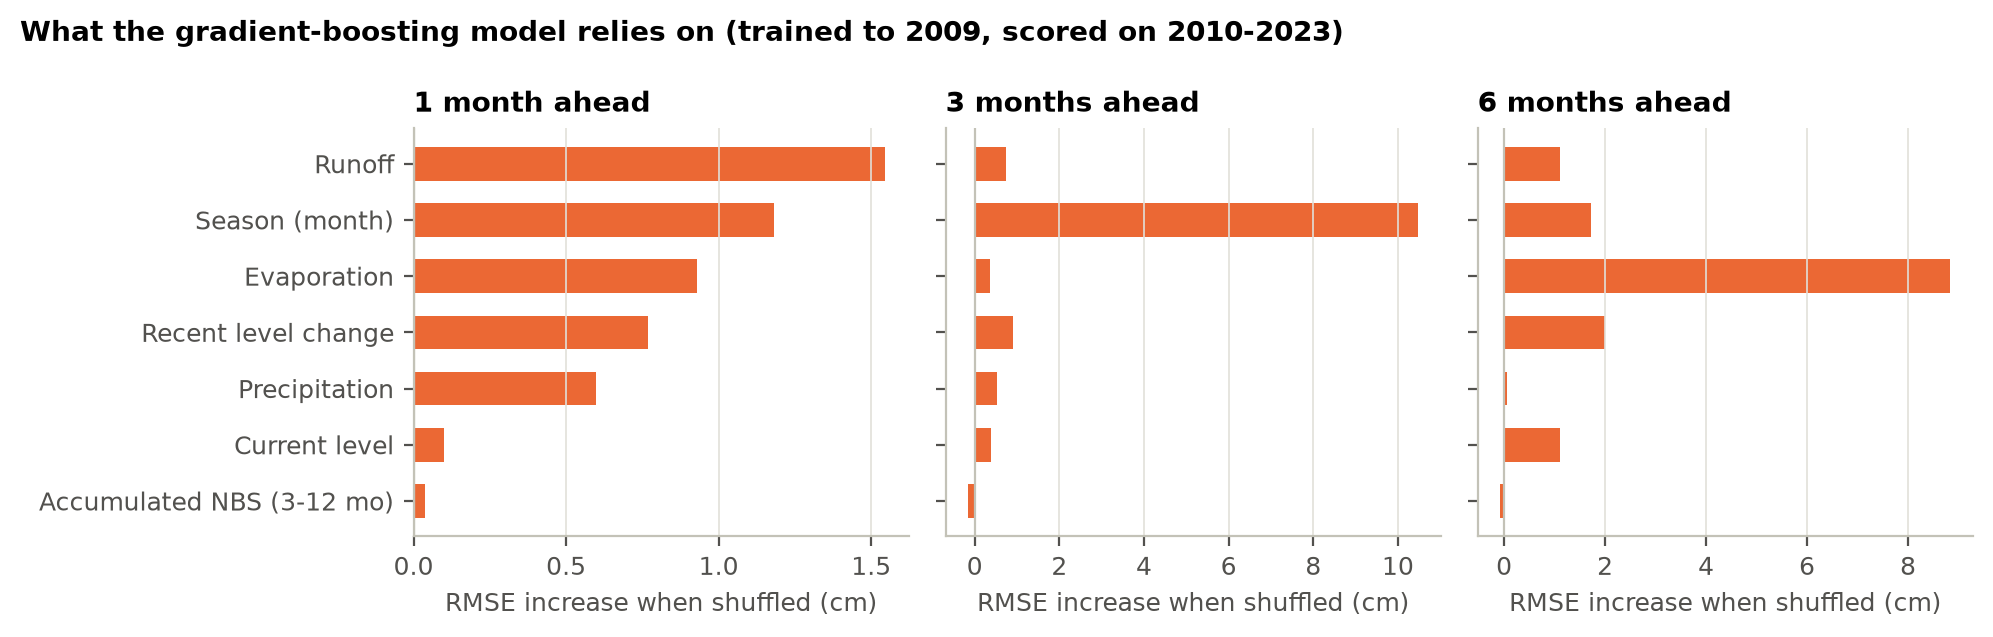

In [22]:
importance = permutation_importance(df)  # ~10 s
importance.to_csv(PROCESSED / "importance.csv", float_format="%.3f")
print(importance.round(2).to_string())
fig4_importance(importance)
display(Image(str(FIGURES / "fig4_feature_importance.png"), width=800))

**Figure 5.** The 2013 low to 2020 high: what the 6-month forecasts did, and which supply term drove the rise.

wrote figures/fig5_case_study_2013_2020.png
  case study: {'level_rise_m': 1.88, 'cum_precip_cm': 79.95, 'cum_minus_evap_cm': -59.49, 'cum_runoff_cm': 82.73}


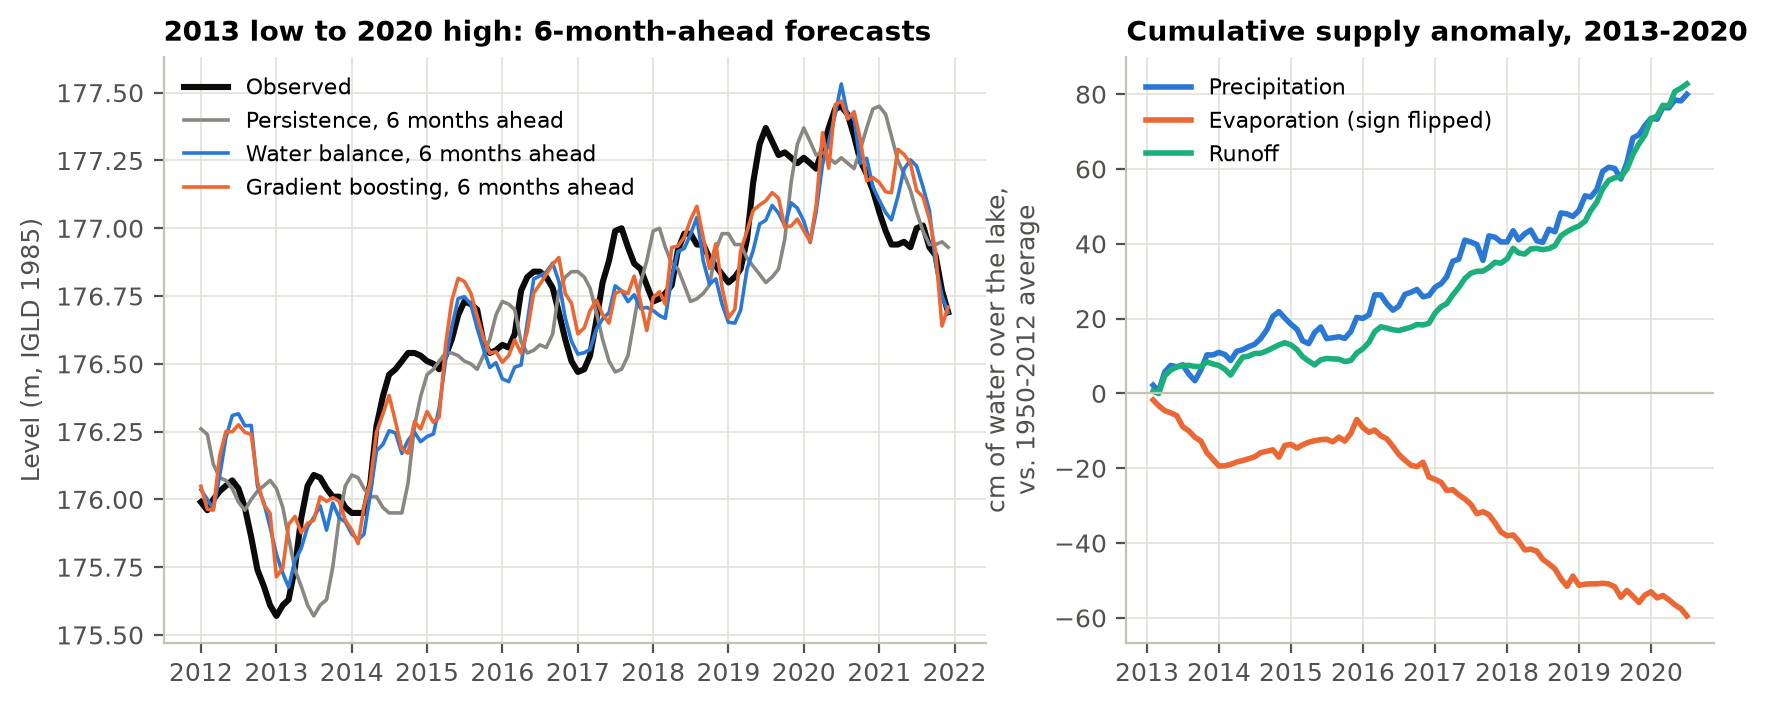

In [23]:
print("  case study:", {k: round(float(v), 2) for k, v in fig5_case_study(df, preds).items()})
display(Image(str(FIGURES / "fig5_case_study_2013_2020.png"), width=800))

**Figure 6.** The physics-guided CNN and how it is coupled to the lake model, drawn from a network trained on 1950-1979.

wrote figures/fig6_cnn_architecture.png


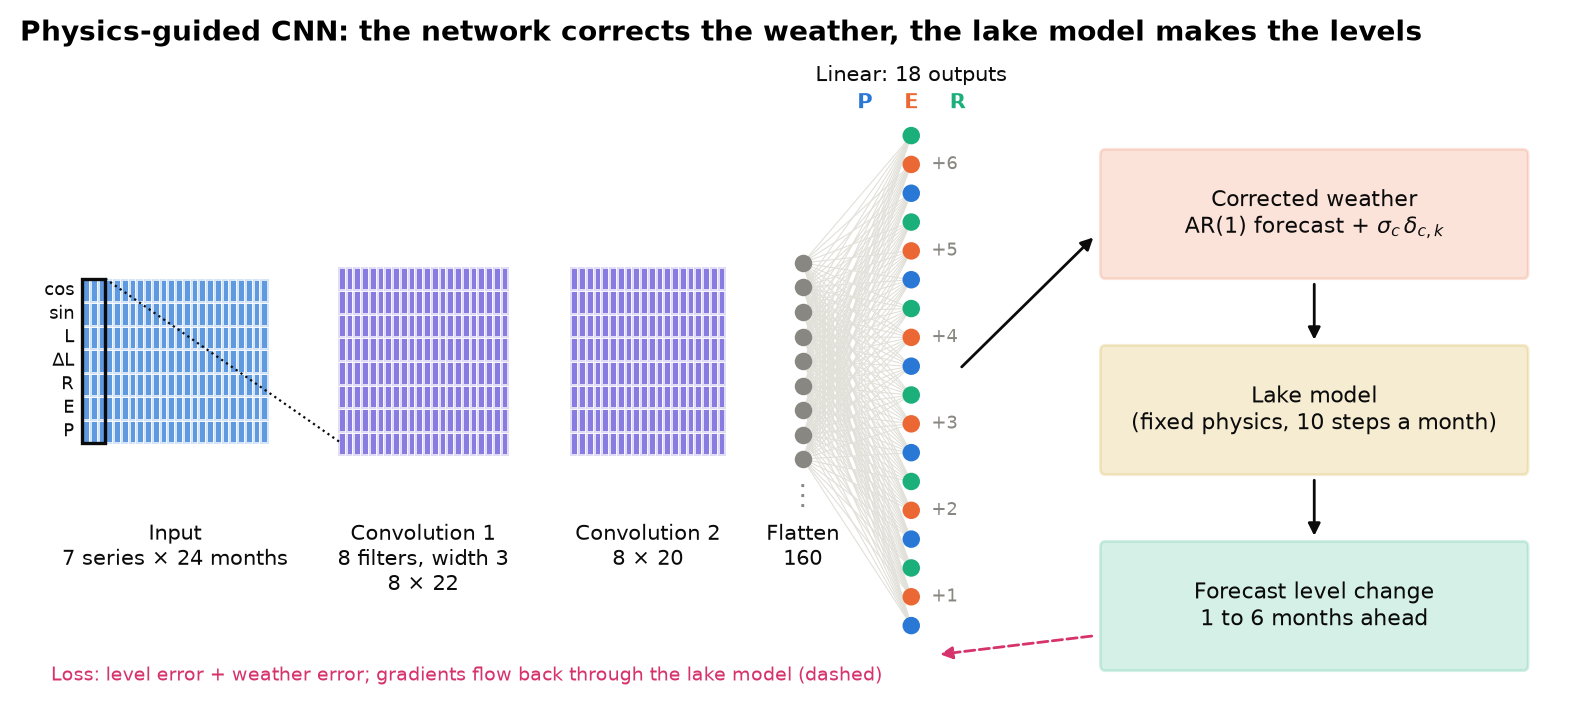

In [24]:
fig6_cnn(PhysicsCNN().fit(df.loc[:"1979-12"]))
display(Image(str(FIGURES / "fig6_cnn_architecture.png"), width=800))

## 8. Numbers quoted in the report

The water-balance coefficients fitted on the full record (saved to
`data/processed/wb_coefficients.csv`), and the RMSE table restricted to the
2013–2020 case-study years.

In [25]:
wb.coefficients().to_csv(PROCESSED / "wb_coefficients.csv", header=["coef"], float_format="%.4f")
print(wb.coefficients().round(3).to_string())
print("  AR(1) of P/E/R anomalies:", dict(zip(COMPONENTS, wb.phi_.round(2).tolist())))

month_1           -82.839
month_2           -78.546
month_3           -93.645
month_4           -78.085
month_5           -67.042
month_6           -74.861
month_7           -84.620
month_8          -110.054
month_9          -128.804
month_10         -135.559
month_11         -116.113
month_12          -89.627
precip_mm_lag0      0.354
evap_mm_lag0       -0.433
runoff_mm_lag0      1.224
precip_mm_lag1      0.531
evap_mm_lag1       -0.374
runoff_mm_lag1      0.607
level_m           -22.985
  AR(1) of P/E/R anomalies: {'precip_mm': 0.02, 'evap_mm': 0.26, 'runoff_mm': 0.45}


In [26]:
case = preds[(preds["target"] >= "2013-01") & (preds["target"] <= "2020-12")]
print("RMSE (cm), targets 2013-2020 only")
print(rmse_table(case).round(2).to_string())

RMSE (cm), targets 2013-2020 only
horizon                                       1      2      3      4      5      6
model                                                                             
Persistence                                7.00  12.94  17.88  21.84  24.75  26.65
Seasonal climatology                       4.04   6.99   9.41  11.76  14.01  16.14
Water balance                              2.89   5.96   8.33  10.54  12.86  15.02
Water balance + snowpack                   2.90   5.93   8.30  10.50  12.87  15.01
Lake model                                 2.91   5.97   8.34  10.56  12.90  15.07
Lake model + snowpack                      2.90   5.91   8.28  10.51  12.89  15.06
Gradient boosting                          3.04   6.18   8.39  10.63  12.69  14.64
Gradient boosting + snowpack               3.00   6.17   8.63  10.90  13.51  15.47
Hybrid (WB + GB residual)                  3.03   6.11   8.27  10.58  12.57  14.67
Physics-guided CNN                         2.91   5.9